# 12 – Karte des ganzen Gebiets: Was findet die Methode überall?

**Ziel.** Die vier Netze auf **alle** 691 Ausschnitte anwenden und daraus eine Karte machen: gemeldete Flächen, daraus Plätze als Punkte, der Abgleich mit der Ground Truth. Das Ergebnis ist je Lauf ein GeoPackage. Notebook 13 baut daraus das Dashboard.

**Warum.** Die Auswertung (Notebooks 08 bis 10) betrifft nur die 15 Testblöcke. Wer wissen will, was die Methode in einer bestimmten Strasse findet, braucht die Karte des ganzen Gebiets.

**Das ist keine Prüfung.** In den Lernblöcken kennt das Netz die Stellen, und an den Validierblöcken wurden Epoche und Schwelle gewählt. Ehrlich geprüft ist die Methode nur in den Testblöcken. Vergleich mit der Schule: Wer die Übungsaufgaben noch einmal löst, zeigt nicht, wie gut er neue Aufgaben löst. Darum trägt hier jede Zahl die Rolle ihres Blocks, und die Kennzahlen des Pilots bleiben die aus Notebook 10.

**Eingestellt wird hier nichts.** Netze, Schwellen und Zählformel stammen unverändert aus den Notebooks 03 und 07. Die Regeln für die Karte stehen in `01b`, Abschnitt 11.3, und wurden vor dem Rechnen festgelegt.

**Schalter.** Die Vorhersage für alle Ausschnitte dauert rund eine halbe Stunde (Grafikkarte). Sie startet nur mit `KARTIERUNG=1`. Ohne Schalter verwendet das Notebook die gespeicherten Masken.

**Eingaben:** die Netze und Schwellen (Notebook 07), `aufteilung.csv` (Notebook 02), `platzmasse.json` (Notebook 03), `kaestchen.gpkg` (Notebook 04), die Luftbilder beider Jahre; für die Kontrollen die Masken aus Notebook 08, die Lösung je Pixel aus Notebook 05 und `zaehlung.csv` aus Notebook 09.
**Ausgaben:** `ergebnisse/dashboard/daten/parkplaetze_{Lauf}.gpkg` (vier Dateien), `ergebnisse/karte_zusammenfassung.csv`, Masken in `ergebnisse/masken_gebiet/` (nur lokal), Abbildungen `12_…`.

In [1]:
import json                        # Einstellungen, Schwellen und Platzmasse lesen
import os                          # Umgebungsvariable KARTIERUNG lesen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ERG = ROOT / "ergebnisse"                            # Ergebnisse
ABB = ERG / "abbildungen"                            # Abbildungen
MASKEN = ERG / "masken_gebiet"                       # gemeldete Parkfläche je Ausschnitt, ganzes Gebiet (nur lokal)
DATEN = ERG / "dashboard" / "daten"                  # GeoPackages für das Dashboard
DATEN.mkdir(parents=True, exist_ok=True)

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
CRS, KACHEL_PX, VERSUCHE, AUFLOESUNGEN_CM, CODE = EINST["CRS"], EINST["KACHEL_PX"], EINST["VERSUCHE"], EINST["AUFLOESUNGEN_CM"], EINST["CODE"]
SCHWELLEN = json.loads((ERG / "schwellen.json").read_text(encoding="utf-8"))    # Schwelle je Lauf (Notebook 07, eingefroren)
MASSE = json.loads((VERARB / "platzmasse.json").read_text(encoding="utf-8"))    # Platzmasse aus Notebook 03
print("Schwelle je Lauf (aus Notebook 07):", {lauf: werte["schwelle"] for lauf, werte in SCHWELLEN.items()})

Schwelle je Lauf (aus Notebook 07): {'A_10cm': 0.4, 'B_10cm': 0.5, 'A_5cm': 0.45, 'B_5cm': 0.35, 'A_10cm_lang': 0.4}


Die Pakete für Raster, Formen und das Netz:

In [2]:
import numpy as np                 # Pixelraster und Rechnen
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildungen
import rasterio                    # Luftbilder lesen
from rasterio.merge import merge   # Ausschnitt aus mehreren Bilddateien zusammensetzen
from rasterio.features import shapes, rasterize    # Raster zurück in Formen; Formen in ein Raster zeichnen
from rasterio.transform import from_origin         # Lage eines Rasters festlegen
from shapely.geometry import shape, box, Point     # Form aus einer Beschreibung; Rechteck; Punkt
from shapely.ops import nearest_points             # nächster Punkt einer Form
import torch                       # neuronale Netze
from netz import GERAET, MITTEL, STREUUNG, lade_modell   # Bauplan und Laden des Netzes (Datei netz.py)

**Einstellungen dieses Schritts.** Die ersten vier sind die Werte der Notebooks 08 und 09. Die letzten zwei gehören zur Karte (`01b`, Abschnitt 11.3, K6).

| Einstellung | Wert | Bedeutung |
| --- | --- | --- |
| `RAND_PX`, `SCHRITT_PX` | 256 und 256 Pixel | Rand um den Ausschnitt und Schritt der Fenster, wie in Notebook 08 |
| `KACHEL_M` | 51,2 m | Seitenlänge eines Ausschnitts |
| `LAEUFE` | vier | Bild 2021 und 2024/25, je 5 cm und 10 cm |
| `ANTEIL_ERKANNT` | 0,5 | Ein Feld gilt als erkannt, wenn mindestens die Hälfte seines Kästchens gemeldet ist (gesetzt; `01b`, 4.10) |
| `NAH_M` | 1 m | Eine Fläche gilt als bestätigt, wenn der Ring eines sichtbaren Feldes in ihr oder höchstens 1 m daneben liegt (gesetzt) |
| `KLEIN_AEQ` | 0,5 | Flächen unter einem halben Platz-Äquivalent stehen nicht einzeln im GeoPackage (`01b`, 11.3, K10). Für die Zählung zählen sie trotzdem |

In [3]:
RAND_PX = 256
SCHRITT_PX = 256
KACHEL_M = 51.2
ANTEIL_ERKANNT = 0.5
NAH_M = 1.0
KLEIN_AEQ = 0.5
LAEUFE = [(versuch, cm, f"{versuch}_{cm}cm") for versuch in VERSUCHE for cm in AUFLOESUNGEN_CM]   # (Versuch, Auflösung, Name)
KARTIERUNG = os.environ.get("KARTIERUNG") == "1"                     # die Vorhersage für alle Ausschnitte startet nur mit Schalter
print("Läufe:", [lauf for _, _, lauf in LAEUFE], "| Vorhersage neu rechnen:", KARTIERUNG)

Läufe: ['A_5cm', 'A_10cm', 'B_5cm', 'B_10cm'] | Vorhersage neu rechnen: False


## 1. Alle Ausschnitte und ihre Rolle

**Schritt 1: die Aufteilung lesen.** Jeder Ausschnitt gehört zu einem Block, und jeder Block hat seit Notebook 02 eine Rolle: Lernen, Validieren oder Testen.

Vorher: eine Tabelle mit 691 Zeilen → nachher: dieselbe Tabelle mit der Kennung als Index und dem Quadrat jedes Ausschnitts als Geometrie.

In [4]:
aufteilung = pd.read_csv(VERARB / "aufteilung.csv")                  # Notebook 02
quadrate = [box(i * KACHEL_M, j * KACHEL_M, (i + 1) * KACHEL_M, (j + 1) * KACHEL_M) for i, j in zip(aufteilung.i, aufteilung.j)]   # links, unten, rechts, oben
ausschnitte = gpd.GeoDataFrame(aufteilung, geometry=quadrate, crs=CRS).set_index("kachel")
test = ausschnitte[ausschnitte.gruppe == "testen"]                   # Maske und Auswahl: nur Testausschnitte (für die Kontrollen)
print(f"{len(ausschnitte)} Ausschnitte in {ausschnitte.block.nunique()} Blöcken")
ausschnitte.groupby("gruppe").agg(bloecke=("block", "nunique"), ausschnitte=("block", "size"))

691 Ausschnitte in 62 Blöcken


,bloecke,ausschnitte
gruppe,,
lernen,38,467
testen,15,137
validieren,9,87


## 2. Die Vorhersage für alle Ausschnitte

**Schritt 1: das Bild eines Ausschnitts mit Rand lesen.** Dieselben Funktionen wie in Notebook 08: `lies_bild` setzt den Rahmen aus den Bilddateien zusammen (5 cm), `halbiere` mittelt je 2 × 2 Pixel (10 cm).

In [5]:
QUELLEN = {}                                                         # geöffnete Bilddateien je Versuch
for versuch, angaben in VERSUCHE.items():
    QUELLEN[versuch] = [rasterio.open(pfad) for pfad in sorted((ROH / "orthofoto" / angaben["ordner"]).glob("*.tif"))]
print({versuch: len(dateien) for versuch, dateien in QUELLEN.items()}, "Bilddateien je Versuch geöffnet")

{'A': 6, 'B': 9} Bilddateien je Versuch geöffnet


Die erste Funktion liest einen Rahmen aus den Bilddateien, bei 5 cm je Pixel:

In [6]:
def lies_bild(versuch, rahmen):
    # Liest den Rahmen (links, unten, rechts, oben) bei 5 cm: Rot, Grün, Blau als Zahlen 0 bis 255
    bild, _ = merge(QUELLEN[versuch], bounds=rahmen, res=0.05, indexes=[1, 2, 3])
    return bild

Die zweite macht aus dem 5-cm-Bild das 10-cm-Bild, genau wie in Notebook 05:

In [7]:
def halbiere(bild):
    # Mittelt je 2 × 2 Pixel: aus 5 cm wird 10 cm
    kanaele, hoehe, breite = bild.shape
    bloecke = bild.reshape(kanaele, hoehe // 2, 2, breite // 2, 2).astype("uint16")
    return ((bloecke.sum(axis=(2, 4)) + 2) // 4).astype("uint8")

In [8]:
def bild_mit_rand(versuch, ausschnitt, aufloesung_cm):
    # Bild eines Ausschnitts samt Rand von 256 Pixeln, in der verlangten Auflösung (wie Notebook 08)
    rand_m = RAND_PX * aufloesung_cm / 100                           # 12,8 m bei 5 cm, 25,6 m bei 10 cm
    links, unten = ausschnitt.i * KACHEL_M - rand_m, ausschnitt.j * KACHEL_M - rand_m
    bild = lies_bild(versuch, (links, unten, links + KACHEL_M + 2 * rand_m, unten + KACHEL_M + 2 * rand_m))
    return bild if aufloesung_cm == 5 else halbiere(bild)

print("Ein Bild mit Rand, 10 cm:", bild_mit_rand("A", ausschnitte.iloc[0], 10).shape, "(Farben, Zeilen, Spalten)")

Ein Bild mit Rand, 10 cm: (3, 1024, 1024) (Farben, Zeilen, Spalten)


**Schritt 2: überlappende Fenster und Meldung.** Wie in Notebook 08: Für jeden Pixel wird der Unterschied der Rohwerte (Parkfläche − keine) über alle Fenster gemittelt. Gemeldet wird ein Pixel, wenn der Unterschied grösser ist als $\ln\big(\tau / (1 - \tau)\big)$; $\tau$ ist die Schwelle des Laufs.

In [9]:
@torch.no_grad()                                                     # nur anwenden, nicht lernen
def meldung(modell, bild, schwelle):
    # Karte "Parkfläche gemeldet" (True/False) für den Ausschnitt ohne Rand
    _, hoehe, breite = bild.shape
    summe = np.zeros((hoehe, breite), np.float32)                    # Summe der Unterschiede je Pixel
    anzahl = np.zeros((hoehe, breite), np.float32)                   # Zahl der Fenster je Pixel
    normiert = (torch.from_numpy(bild).float() / 255.0 - MITTEL) / STREUUNG      # wie beim Lernen (Notebook 07)
    for z in range(0, hoehe - KACHEL_PX + 1, SCHRITT_PX):            # Fenster von oben nach unten
        for s in range(0, breite - KACHEL_PX + 1, SCHRITT_PX):       # und von links nach rechts
            fenster = normiert[:, z:z + KACHEL_PX, s:s + KACHEL_PX].unsqueeze(0).to(GERAET)
            with torch.autocast(GERAET, dtype=torch.float16, enabled=GERAET == "cuda"):
                rohwerte = modell(fenster)[0].float()                # [2, 512, 512]
            summe[z:z + KACHEL_PX, s:s + KACHEL_PX] += (rohwerte[1] - rohwerte[0]).cpu().numpy()
            anzahl[z:z + KACHEL_PX, s:s + KACHEL_PX] += 1
    grenze = np.log(schwelle / (1 - schwelle))                       # Schwelle der Sicherheit, umgerechnet auf den Unterschied
    return (summe / anzahl)[RAND_PX:-RAND_PX, RAND_PX:-RAND_PX] > grenze

**Schritt 3: alle Ausschnitte, alle vier Läufe.** Nur mit dem Schalter `KARTIERUNG=1`. Je Ausschnitt wird die Karte der Meldung gespeichert.

Vorher: 691 Ausschnitte → nachher: je Lauf 691 Masken.

In [10]:
if KARTIERUNG:
    for versuch, cm, lauf in LAEUFE:
        (MASKEN / lauf).mkdir(parents=True, exist_ok=True)
        modell = lade_modell(lauf)                                   # bester Stand dieses Laufs (Notebook 07)
        for ausschnitt in aufteilung.itertuples():
            gemeldet = meldung(modell, bild_mit_rand(versuch, ausschnitt, cm), SCHWELLEN[lauf]["schwelle"])
            np.savez_compressed(MASKEN / lauf / f"{ausschnitt.kachel}.npz", gemeldet=gemeldet)
        del modell
        torch.cuda.empty_cache()                                     # Grafikspeicher freigeben
        print(lauf, "fertig")
else:
    print("Keine neue Vorhersage (KARTIERUNG nicht gesetzt). Es werden die gespeicherten Masken verwendet.")
print({lauf: len(list((MASKEN / lauf).glob("*.npz"))) for _, _, lauf in LAEUFE}, "Masken je Lauf")

Keine neue Vorhersage (KARTIERUNG nicht gesetzt). Es werden die gespeicherten Masken verwendet.
{'A_5cm': 691, 'A_10cm': 691, 'B_5cm': 691, 'B_10cm': 691} Masken je Lauf


**Kontrolle 1: Stimmen die Masken der Testausschnitte mit Notebook 08 überein?** Für die 137 Testausschnitte gibt es die Masken schon aus Notebook 08. Die neue Vorhersage muss dort Pixel für Pixel dasselbe liefern.

In [11]:
def lies_maske(lauf, kachel):
    return np.load(MASKEN / lauf / f"{kachel}.npz")["gemeldet"]      # gemeldete Parkfläche eines Ausschnitts

for _, _, lauf in LAEUFE:
    gleich = sum(np.array_equal(lies_maske(lauf, kachel), np.load(ERG / "masken" / lauf / f"{kachel}.npz")["gemeldet"]) for kachel in test.index)
    print(f"Kontrolle 1, {lauf}: {gleich} von {len(test)} Masken der Testausschnitte sind gleich wie in Notebook 08")
    assert gleich == len(test), "Die Vorhersage weicht von Notebook 08 ab."

Kontrolle 1, A_5cm: 137 von 137 Masken der Testausschnitte sind gleich wie in Notebook 08
Kontrolle 1, A_10cm: 137 von 137 Masken der Testausschnitte sind gleich wie in Notebook 08


Kontrolle 1, B_5cm: 137 von 137 Masken der Testausschnitte sind gleich wie in Notebook 08
Kontrolle 1, B_10cm: 137 von 137 Masken der Testausschnitte sind gleich wie in Notebook 08


## 3. Die Kategorie je Pixel, für die Karte

**Worum es geht.** Gezählt wird nur, was auf **bewerteten** Stellen gemeldet ist (`01b`, 12.8). Was das Netz auf verdeckten oder unsicheren Stellen, auf Streifen und bei einzeln stehenden Feldern meldet, zählt nicht und wird getrennt gezeigt. Dafür braucht es je Pixel die Kategorie der Ground Truth.

**Ein Unterschied zu Notebook 05.** Dort wird in Lern- und Validier-Ausschnitten zusätzlich ein Rand von 25 m um die Testblöcke ausgeblendet. Das dient nur dem Lernen. Für die Karte malen wir die Kategorien **ohne** diesen Rand (`01b`, 11.3, K4). Die Reihenfolge ist dieselbe: zuerst die nicht bewerteten Kategorien, dann die sichtbaren Felder; überlappen sie sich, gewinnt das sichtbare.

In [12]:
kaestchen = gpd.read_file(VERARB / "kaestchen.gpkg")                 # Kästchen aller Felder mit Kategorie je Bild (Notebook 04)

def kategorie_raster(kachel, spalte, pixel_m):
    # Malt die Felder eines Ausschnitts auf ein Raster; der Wert jedes Pixels ist der Code seiner Kategorie
    links, unten, rechts, oben = ausschnitte.geometry[kachel].bounds
    seite_px = int(round(KACHEL_M / pixel_m))                        # 1024 Pixel bei 5 cm, 512 bei 10 cm
    nahe = kaestchen[kaestchen.intersects(ausschnitte.geometry[kachel])]         # Felder, die den Ausschnitt berühren
    formen = [(form, CODE[kategorie]) for form, kategorie in zip(nahe.geometry, nahe[spalte]) if kategorie not in ("kein Parkfeld", "sichtbar")]   # 1. nicht bewertet
    formen += [(form, CODE["sichtbar"]) for form in nahe[nahe[spalte] == "sichtbar"].geometry]                                                    # 2. sichtbar übermalt
    if not formen:
        return np.zeros((seite_px, seite_px), dtype="uint8")         # Ausschnitt ohne Feld: alles 0
    return rasterize(formen, out_shape=(seite_px, seite_px), transform=from_origin(links, oben, pixel_m, pixel_m), fill=0, dtype="uint8")

**Kontrolle 2: Stimmt das Raster in den Testausschnitten mit Notebook 05 überein?** Testausschnitte haben keinen ausgeblendeten Rand. Dort muss unser Raster genau die Lösung je Pixel aus Notebook 05 ergeben.

In [13]:
for versuch, cm, lauf in LAEUFE:
    spalte = VERSUCHE[versuch]["kategorie"]                          # Spalte der Kategorie für dieses Bild
    gleich = sum(np.array_equal(kategorie_raster(kachel, spalte, cm / 100), np.load(VERARB / "loesung" / lauf / f"{kachel}.npz")["kategorie"]) for kachel in test.index)
    print(f"Kontrolle 2, {lauf}: {gleich} von {len(test)} Rastern der Testausschnitte sind gleich wie in Notebook 05")
    assert gleich == len(test), "Die Kategorie je Pixel weicht von Notebook 05 ab."

Kontrolle 2, A_5cm: 137 von 137 Rastern der Testausschnitte sind gleich wie in Notebook 05


Kontrolle 2, A_10cm: 137 von 137 Rastern der Testausschnitte sind gleich wie in Notebook 05


Kontrolle 2, B_5cm: 137 von 137 Rastern der Testausschnitte sind gleich wie in Notebook 05


Kontrolle 2, B_10cm: 137 von 137 Rastern der Testausschnitte sind gleich wie in Notebook 05


## 4. Von der Maske zu Flächen

**Schritt 1: die Funktion.** Wie in Notebook 09: Eine Maske wird in zusammenhängende Flächen zerlegt. Jede Fläche bekommt ihre mittlere Tiefe (Fläche ÷ lange Seite des kleinsten umschliessenden Rechtecks), daraus die Klasse und die Platz-Äquivalente. Hier behalten wir zusätzlich die Form der Fläche: Sie kommt auf die Karte.

In [14]:
def flaechen_tabelle(maske, kachel, pixel_m):
    # Zerlegt eine Maske in zusammenhängende Flächen. Je Fläche: Form, Grösse, mittlere Tiefe, Klasse, Platz-Äquivalente
    links, oben = ausschnitte.i[kachel] * KACHEL_M, (ausschnitte.j[kachel] + 1) * KACHEL_M   # linke obere Ecke des Ausschnitts in Metern
    zeilen = []
    for beschreibung, _ in shapes(maske.astype("uint8"), mask=maske, transform=from_origin(links, oben, pixel_m, pixel_m)):
        flaeche = shape(beschreibung)                                # eine zusammenhängende Fläche in Landeskoordinaten
        ecken = np.array(flaeche.minimum_rotated_rectangle.exterior.coords)      # kleinstes umschliessendes Rechteck
        kanten = ecken[1:3] - ecken[0:2]                             # seine zwei Kanten als Vektoren
        tiefe = flaeche.area / np.hypot(kanten[:, 0], kanten[:, 1]).max()        # mittlere Tiefe
        klasse = "eng" if tiefe > MASSE["TIEFE_GRENZE_M"] else "weit"
        zeilen.append(dict(kachel=kachel, flaeche_m2=flaeche.area, tiefe_m=tiefe, klasse=klasse, aequivalente=flaeche.area / MASSE[klasse]["flaeche_m2"], geometry=flaeche))
    return zeilen

**Schritt 2: alle Ausschnitte, alle vier Läufe.** Je Ausschnitt entstehen zwei Gruppen von Flächen:

| Gruppe | Meldung liegt auf … | zählt |
| --- | --- | --- |
| `gezählt` | bewerteten Stellen (keine Parkfläche oder sichtbares Feld laut Ground Truth) | ja |
| `nicht gezählt` | verdeckten oder unsicheren Stellen, Streifen, einzeln stehenden Feldern | nein |

Vorher: Masken → nachher: eine Tabelle aller gemeldeten Flächen mit ihrer Form.

In [15]:
BEWERTET = [CODE["kein Parkfeld"], CODE["sichtbar"]]                 # nur hier zählt eine Meldung
zeilen = []
for versuch, cm, lauf in LAEUFE:
    spalte = VERSUCHE[versuch]["kategorie"]
    for kachel in ausschnitte.index:
        gemeldet = lies_maske(lauf, kachel)
        bewertet = np.isin(kategorie_raster(kachel, spalte, cm / 100), BEWERTET)
        for teil, maske in [("gezählt", gemeldet & bewertet), ("nicht gezählt", gemeldet & ~bewertet)]:
            for zeile in flaechen_tabelle(maske, kachel, cm / 100):
                zeilen.append(dict(lauf=lauf, teil=teil, **zeile))
    print(lauf, "fertig")
flaechen = gpd.GeoDataFrame(zeilen, crs=CRS)
flaechen["gruppe"] = flaechen.kachel.map(ausschnitte.gruppe)        # Rolle des Blocks, in dem die Fläche liegt
print(f"Gemeldete Flächen insgesamt: {len(flaechen)}")
flaechen.groupby(["lauf", "teil"]).aequivalente.agg(["size", "sum"]).round(1)

A_5cm fertig


A_10cm fertig


B_5cm fertig


B_10cm fertig
Gemeldete Flächen insgesamt: 265651


size     sum
lauf   teil                        
A_10cm gezählt        16929  2704.5
       nicht gezählt   1978   128.7
A_5cm  gezählt        90659  2700.0
       nicht gezählt  11300   146.0
B_10cm gezählt        37536  1623.4
       nicht gezählt   6277   223.0
B_5cm  gezählt        83211  1868.6
       nicht gezählt  17761   275.5

## 5. Die Anzahl je Ausschnitt

**Schritt 1: summieren und einmal runden.** Wie in Notebook 09: Die Platz-Äquivalente der gezählten Flächen werden je Ausschnitt summiert und einmal kaufmännisch gerundet (`np.floor(x + 0.5)`).

Vorher: Tabelle aller Flächen → nachher: eine Zahl je Lauf und Ausschnitt.

In [16]:
gezaehlt_flaechen = flaechen[flaechen.teil == "gezählt"]             # Maske: nur Flächen, die zählen
alle_zeilen = pd.MultiIndex.from_product([[lauf for _, _, lauf in LAEUFE], ausschnitte.index], names=["lauf", "kachel"])
anzahl = gezaehlt_flaechen.groupby(["lauf", "kachel"]).aequivalente.sum().reindex(alle_zeilen).fillna(0).rename("aequivalente").to_frame()   # Ausschnitte ohne Meldung: 0
anzahl["gezaehlt"] = np.floor(anzahl.aequivalente + 0.5).astype(int)   # einmal je Ausschnitt runden
print(f"Vorher: {len(gezaehlt_flaechen)} gezählte Flächen → nachher: {len(anzahl)} Zeilen (4 Läufe × {len(ausschnitte)} Ausschnitte)")
anzahl.groupby("lauf").gezaehlt.sum().to_frame("gezählte Plätze im ganzen Gebiet")

Vorher: 228335 gezählte Flächen → nachher: 2764 Zeilen (4 Läufe × 691 Ausschnitte)


,gezählte Plätze im ganzen Gebiet
lauf,
A_10cm,2693
A_5cm,2700
B_10cm,1616
B_5cm,1866


**Kontrolle 3: Stimmt die Zahl in den Testausschnitten mit Notebook 09 überein?** `zaehlung.csv` enthält die gezählten Plätze der Testausschnitte. Unsere Zahl muss dort in jedem Ausschnitt dieselbe sein.

In [17]:
zaehlung = pd.read_csv(ERG / "zaehlung.csv").set_index(["lauf", "kachel"])     # Notebook 09: nur Testausschnitte
gleich = int((anzahl.gezaehlt.reindex(zaehlung.index) == zaehlung.gezaehlt).sum())
print(f"Kontrolle 3: in {gleich} von {len(zaehlung)} Zeilen (4 Läufe × {len(test)} Testausschnitte) ist die gezählte Zahl gleich wie in Notebook 09")
assert gleich == len(zaehlung), "Die Zählung weicht von Notebook 09 ab."

Kontrolle 3: in 548 von 548 Zeilen (4 Läufe × 137 Testausschnitte) ist die gezählte Zahl gleich wie in Notebook 09


## 6. Von Flächen zu Punkten

**Worum es geht.** Eine Karte mit Flächen sagt nicht auf einen Blick, wie viele Plätze eine Fläche ergibt. Darum bekommt jede gezählte Fläche so viele Punkte, wie sie Plätze ergibt. **Die Punkte sind keine einzeln erkannten Felder:** Das Netz meldet Fläche, und die Punkte werden gleichmässig darauf verteilt.

**Schritt 1: die Zahl eines Ausschnitts auf seine Flächen verteilen.** Die Methode rundet einmal je Ausschnitt. Die Flächen eines Ausschnitts haben aber Bruchteile, zum Beispiel 2,6 und 1,7 Platz-Äquivalente (zusammen 4,3, gerundet 4). Regel (`01b`, 11.3, K5): Jede Fläche bekommt zuerst den ganzen Teil (2 und 1). Die übrigen Plätze (hier 1) gehen der Reihe nach an die Flächen mit dem grössten Rest (hier an die mit 0,7). So ist die Summe genau die gezählte Zahl.

In [18]:
def verteile(aequivalente, gezaehlt):
    # Verteilt die gezählte Zahl eines Ausschnitts auf seine Flächen: erst der ganze Teil, dann die grössten Reste
    ganz = np.floor(aequivalente).astype(int)                        # ganzer Teil je Fläche
    uebrig = gezaehlt - ganz.sum()                                   # so viele Plätze sind noch zu vergeben
    groesste_reste = np.argsort(-(aequivalente - ganz), kind="stable")[:uebrig]   # Nummern der Flächen mit dem grössten Rest
    ganz[groesste_reste] += 1
    return ganz

beispiel = np.array([2.6, 1.7, 0.4])
print("Beispiel:", beispiel, "→ zusammen", beispiel.sum().round(1), "→ gezählt", int(np.floor(beispiel.sum() + 0.5)), "→ verteilt", verteile(beispiel, int(np.floor(beispiel.sum() + 0.5))))

Beispiel: [2.6 1.7 0.4] → zusammen 4.7 → gezählt 5 → verteilt [3 2 0]


**Schritt 2: für alle Ausschnitte.** `groupby` nimmt die gezählten Flächen eines Laufs und Ausschnitts zusammen; `verteile` gibt jeder ihre Zahl Plätze.

Vorher: gezählte Flächen mit Platz-Äquivalenten → nachher: dieselben Flächen mit einer ganzen Zahl Plätze.

In [19]:
flaechen["plaetze"] = 0                                              # nicht gezählte Flächen behalten 0
for (lauf, kachel), gruppe in gezaehlt_flaechen.groupby(["lauf", "kachel"]):
    flaechen.loc[gruppe.index, "plaetze"] = verteile(gruppe.aequivalente.values, anzahl.gezaehlt[(lauf, kachel)])
summe = flaechen.groupby("lauf").plaetze.sum()
assert (summe == anzahl.groupby("lauf").gezaehlt.sum()).all()        # die Punkte ergeben zusammen genau die gezählte Zahl
print("Plätze auf Flächen verteilt; Summe je Lauf:", summe.to_dict())

Plätze auf Flächen verteilt; Summe je Lauf: {'A_10cm': 2693, 'A_5cm': 2700, 'B_10cm': 1616, 'B_5cm': 1866}


**Schritt 3: die Punkte einer Fläche setzen.** Die lange Seite des kleinsten umschliessenden Rechtecks gibt die Richtung der Fläche. Auf seiner Mittellinie liegen die Punkte in gleichen Abständen: bei 2 Plätzen bei einem Viertel und drei Vierteln der Länge. Liegt ein Punkt ausserhalb der Fläche (gebogene Form), wird er auf den nächsten Punkt der Fläche geschoben.

In [20]:
def punkte_entlang(flaeche, n):
    # n Punkte gleichmässig auf der Mittellinie des kleinsten umschliessenden Rechtecks
    ecken = np.array(flaeche.minimum_rotated_rectangle.exterior.coords)[:4]
    seite_a, seite_b = ecken[1] - ecken[0], ecken[2] - ecken[1]      # zwei angrenzende Seiten des Rechtecks
    lang = seite_a if np.hypot(*seite_a) >= np.hypot(*seite_b) else seite_b
    mitte = ecken.mean(axis=0)                                       # Mittelpunkt des Rechtecks
    punkte = []
    for nummer in range(n):
        punkt = Point(mitte + ((nummer + 0.5) / n - 0.5) * lang)     # −0,5 bis +0,5 entlang der langen Seite
        if not flaeche.contains(punkt):
            punkt = nearest_points(flaeche, punkt)[0]                # auf die Fläche schieben
        punkte.append(punkt)
    return punkte

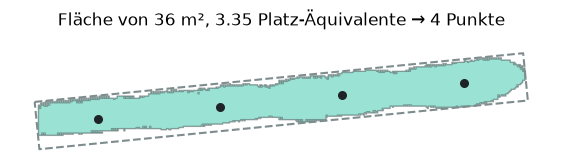

In [21]:
# Abbildung: eine gezählte Fläche mit mehreren Plätzen, ihr umschliessendes Rechteck und die Punkte
beispiel_flaeche = flaechen[(flaechen.lauf == "A_5cm") & (flaechen.plaetze >= 4)].sort_values("flaeche_m2").iloc[0]
fig, ax = plt.subplots(figsize=(7, 3.4))
gpd.GeoSeries([beispiel_flaeche.geometry]).plot(ax=ax, color="#00b894", alpha=0.4, edgecolor="#1d2327")              # gemeldete Fläche
gpd.GeoSeries([beispiel_flaeche.geometry.minimum_rotated_rectangle]).boundary.plot(ax=ax, color="#7f8c8d", linestyle="--")   # umschliessendes Rechteck
gpd.GeoSeries(punkte_entlang(beispiel_flaeche.geometry, int(beispiel_flaeche.plaetze))).plot(ax=ax, color="#1d2327", markersize=30)   # die Punkte
ax.set_title(f"Fläche von {beispiel_flaeche.flaeche_m2:.0f} m², {beispiel_flaeche.aequivalente:.2f} Platz-Äquivalente → {int(beispiel_flaeche.plaetze)} Punkte")
ax.set_aspect("equal"); ax.set_axis_off()
fig.savefig(ABB / "12_punkte.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Grün: eine gemeldete Fläche. Gestrichelt: ihr kleinstes umschliessendes Rechteck. Schwarz: die Punkte auf der Mittellinie. Die Punkte stehen in gleichen Abständen; wo genau die einzelnen Felder aufgemalt sind, weiss die Methode nicht.

## 7. Abgleich mit der Ground Truth

**Schritt 1: Ist ein sichtbares Feld erkannt?** Für jedes Feld, das im Bild des Laufs sichtbar ist, rechnen wir, welcher Anteil seines Kästchens gemeldet ist: Fläche der Überschneidung mit den gemeldeten Flächen ÷ Fläche des Kästchens. Ab der Hälfte gilt es als `erkannt`, sonst als `übersehen`. Felder der übrigen Kategorien sind `nicht bewertet`.

`sindex.query` findet schnell die gemeldeten Flächen, die ein Kästchen berühren; nur mit ihnen wird die Überschneidung gerechnet.

In [22]:
def anteil_gemeldet(felder, gemeldete):
    # Anteil jedes Kästchens, der in gemeldeten Flächen liegt
    anteile = []
    for kasten in felder.geometry:
        nummern = gemeldete.sindex.query(kasten, predicate="intersects")         # gemeldete Flächen, die das Kästchen berühren
        anteile.append(sum(kasten.intersection(gemeldete.geometry.iloc[nummer]).area for nummer in nummern) / kasten.area)
    return np.array(anteile)

felder_je_lauf = {}                                                  # je Lauf: die Felder der Ground Truth mit ihrem Status
for versuch, cm, lauf in LAEUFE:
    felder = kaestchen.rename(columns={VERSUCHE[versuch]["kategorie"]: "kategorie"})[["id", "kachel", "gruppe", "form", "klasse", "strassenraum", "kategorie", "x", "y", "geometry"]].copy()
    felder = felder[felder.kategorie != "kein Parkfeld"].reset_index(drop=True)   # in diesem Bild ist dort kein Feld aufgemalt
    felder["anteil_gemeldet"] = anteil_gemeldet(felder, flaechen[flaechen.lauf == lauf]).round(3)
    felder["status"] = np.select([felder.kategorie != "sichtbar", felder.anteil_gemeldet >= ANTEIL_ERKANNT], ["nicht bewertet", "erkannt"], default="übersehen")
    felder_je_lauf[lauf] = felder
pd.DataFrame({lauf: felder.status.value_counts() for lauf, felder in felder_je_lauf.items()}).T

status,erkannt,nicht bewertet,übersehen
A_5cm,2384,518,324
A_10cm,2325,518,383
B_5cm,1580,1318,253
B_10cm,1271,1318,562


**Schritt 2: Ist eine gezählte Fläche bestätigt?** Eine gezählte Fläche gilt als `bestätigt`, wenn in ihr oder höchstens 1 m daneben der Ring eines sichtbaren Feldes liegt; sonst als `zusätzlich gemeldet`. `buffer(1)` macht die Fläche ringsum 1 m grösser; `sjoin` sucht die Ringe darin.

"Zusätzlich gemeldet" heisst nicht automatisch "falsch": Es kann eine Fehlmeldung sein oder ein Feld, das in der Ground Truth fehlt.

Vorher: gezählte Flächen → nachher: dieselben Flächen mit der Angabe bestätigt (ja oder nein).

In [23]:
flaechen["bestaetigt"] = False
for _, _, lauf in LAEUFE:
    sichtbar = felder_je_lauf[lauf][felder_je_lauf[lauf].kategorie == "sichtbar"]
    ringe = gpd.GeoDataFrame(geometry=gpd.points_from_xy(sichtbar.x, sichtbar.y), crs=CRS)          # Ringe der sichtbaren Felder
    eigene = flaechen[(flaechen.lauf == lauf) & (flaechen.teil == "gezählt")]
    vergroessert = gpd.GeoDataFrame(geometry=eigene.buffer(NAH_M), index=eigene.index, crs=CRS)     # jede Fläche um 1 m vergrössert
    treffer = gpd.sjoin(vergroessert, ringe, predicate="intersects", how="inner")                    # Flächen mit mindestens einem Ring
    flaechen.loc[treffer.index.unique(), "bestaetigt"] = True
flaechen[flaechen.teil == "gezählt"].groupby(["lauf", "bestaetigt"]).plaetze.sum().unstack().rename(columns={True: "Plätze bestätigt", False: "Plätze zusätzlich gemeldet"})

bestaetigt,Plätze zusätzlich gemeldet,Plätze bestätigt
lauf,,
A_10cm,84,2609
A_5cm,102,2598
B_10cm,84,1532
B_5cm,125,1741


## 8. Speichern: ein GeoPackage je Lauf

**Schritt 1: Was steht einzeln in der Datei?** Die Methode meldet sehr viele Flächen, und die meisten sind winzig: einzelne Pixel am Rand eines Feldes. Sie zählen mit (es gibt keinen Filter, `01b`, 12.8), tragen zusammen aber nur einen kleinen Teil der Platz-Äquivalente bei. Einzeln gespeichert würden sie die Dateien sehr gross machen. Regel (`01b`, 11.3, K10): Einzeln gespeichert wird eine Fläche, wenn sie mindestens ein halbes Platz-Äquivalent hat oder wenn ihr ein Platz zugeteilt ist. Die Platz-Äquivalente der übrigen Flächen werden je Ausschnitt summiert und stehen dort als eigene Zahl. Die Zählung ändert sich dadurch nicht.

Vorher: alle gemeldeten Flächen → nachher: die einzeln gespeicherten Flächen und, je Lauf, was die kleinen zusammen ausmachen.

In [24]:
flaechen["einzeln"] = (flaechen.plaetze >= 1) | (flaechen.aequivalente >= KLEIN_AEQ)         # Maske: Flächen, die einzeln gespeichert werden
gez = flaechen[flaechen.teil == "gezählt"]
klein = pd.DataFrame({"flaechen_gezaehlt": gez.groupby("lauf").size(), "davon_einzeln_gespeichert": gez[gez.einzeln].groupby("lauf").size(),
                      "aequivalente_gesamt": gez.groupby("lauf").aequivalente.sum(), "aequivalente_der_kleinen": gez[~gez.einzeln].groupby("lauf").aequivalente.sum()})
klein["anteil_der_kleinen"] = klein.aequivalente_der_kleinen / klein.aequivalente_gesamt     # so viel der Zählung steckt in den kleinen Flächen
klein.round(3)

,flaechen_gezaehlt,davon_einzeln_gespeichert,aequivalente_gesamt,aequivalente_der_kleinen,anteil_der_kleinen
lauf,,,,,
A_10cm,16929,750,2704.541,58.311,0.022
A_5cm,90659,806,2700.032,67.056,0.025
B_10cm,37536,566,1623.376,92.260,0.057
B_5cm,83211,668,1868.608,79.680,0.043


**Wie man die Tabelle liest.** `flaechen_gezaehlt` sind alle Flächen, die in die Zählung eingehen. `davon_einzeln_gespeichert` stehen einzeln in der Datei. `anteil_der_kleinen` ist der Teil der Platz-Äquivalente, der in den kleinen Flächen steckt; er steht je Ausschnitt in der Spalte `aeq_kleinflaechen`.

**Schritt 2: die Dateien schreiben.** Jede Datei hat vier Ebenen, in Schweizer Koordinaten (LV95):

| Ebene | Inhalt | wichtigste Spalten |
| --- | --- | --- |
| `gemeldete_flaechen` | was das Netz als Parkfläche meldet, ab einem halben Platz-Äquivalent | `teil` (gezählt oder nicht), `klasse`, `flaeche_m2`, `aequivalente`, `plaetze`, `bestaetigt`, `gruppe` |
| `plaetze` | die Punkte aus Abschnitt 6 | `status` (bestätigt oder zusätzlich gemeldet), `platz`, `gruppe` |
| `ausschnitte` | die 691 Quadrate | `gruppe` (Rolle des Blocks), `gezaehlt`, `aequivalente` (alle gezählten Flächen), `aeq_kleinflaechen` (davon in Flächen, die nicht einzeln gespeichert sind), `sichtbar_ground_truth` |
| `felder_ground_truth` | die Kästchen der von Hand gesetzten Felder | `kategorie`, `form`, `status` (erkannt, übersehen, nicht bewertet), `anteil_gemeldet` |

Vorher: Tabellen im Arbeitsspeicher → nachher: vier Dateien in `ergebnisse/dashboard/daten/`.

In [25]:
def punkte_der_flaechen(eigene):
    # Setzt die Plätze jeder Fläche als Punkte auf ihre Mittellinie: eine Zeile je Platz
    zeilen = []
    for flaeche in eigene[eigene.plaetze > 0].itertuples():
        for nummer, punkt in enumerate(punkte_entlang(flaeche.geometry, flaeche.plaetze), start=1):
            zeilen.append(dict(kachel=flaeche.kachel, gruppe=flaeche.gruppe, status="bestätigt" if flaeche.bestaetigt else "zusätzlich gemeldet",
                               platz=f"{nummer} von {flaeche.plaetze}", flaeche_m2=flaeche.flaeche_m2, geometry=punkt))
    return gpd.GeoDataFrame(zeilen, crs=CRS)

Die zweite Funktion zählt für die Übersicht aus, je Rolle der Blöcke:

In [26]:
def zaehle_je_rolle(lauf, quadrate, felder, punkte):
    # Zählt je Rolle der Blöcke aus, was die Karte zeigt: eine Zeile für Lernen, eine für Validieren, eine für Testen
    zeilen = []
    for gruppe in ["lernen", "validieren", "testen"]:
        zeilen.append(dict(lauf=lauf, gruppe=gruppe, ausschnitte=int((quadrate.gruppe == gruppe).sum()), sichtbar_ground_truth=int(quadrate.sichtbar_ground_truth[quadrate.gruppe == gruppe].sum()),
                           gezaehlt=int(quadrate.gezaehlt[quadrate.gruppe == gruppe].sum()), erkannt=int(((felder.gruppe == gruppe) & (felder.status == "erkannt")).sum()),
                           uebersehen=int(((felder.gruppe == gruppe) & (felder.status == "übersehen")).sum()), zusaetzlich_gemeldet=int(((punkte.gruppe == gruppe) & (punkte.status == "zusätzlich gemeldet")).sum())))
    return zeilen

Jetzt die Schleife über die vier Läufe: Flächen auswählen, Punkte setzen, Zahlen je Ausschnitt zusammenstellen, die vier Ebenen speichern.

In [27]:
uebersicht = []
for versuch, cm, lauf in LAEUFE:
    eigene = flaechen[flaechen.lauf == lauf].drop(columns="lauf")
    kleine = eigene[(eigene.teil == "gezählt") & ~eigene.einzeln].groupby("kachel").aequivalente.sum()   # Platz-Äquivalente der kleinen Flächen je Ausschnitt
    eigene = eigene[eigene.einzeln].drop(columns="einzeln")           # nur diese Flächen stehen einzeln in der Datei
    eigene = eigene.assign(flaeche_m2=eigene.flaeche_m2.round(2), tiefe_m=eigene.tiefe_m.round(2), aequivalente=eigene.aequivalente.round(3))
    punkte = punkte_der_flaechen(eigene)
    felder = felder_je_lauf[lauf]
    quadrate = ausschnitte[["block", "gruppe", "geometry"]].copy()
    quadrate["gezaehlt"] = anzahl.gezaehlt[lauf].reindex(quadrate.index)
    quadrate["aequivalente"] = anzahl.aequivalente[lauf].reindex(quadrate.index).round(3)
    quadrate["aeq_kleinflaechen"] = kleine.reindex(quadrate.index).fillna(0).round(3)
    quadrate["sichtbar_ground_truth"] = felder[felder.kategorie == "sichtbar"].kachel.value_counts().reindex(quadrate.index).fillna(0).astype(int)
    datei = DATEN / f"parkplaetze_{lauf}.gpkg"
    datei.unlink(missing_ok=True)                                    # alte Datei entfernen, damit keine alte Ebene übrig bleibt
    for name, tabelle in [("gemeldete_flaechen", eigene), ("plaetze", punkte), ("ausschnitte", quadrate.reset_index()), ("felder_ground_truth", felder)]:
        tabelle.to_file(datei, layer=name, driver="GPKG")
    uebersicht += zaehle_je_rolle(lauf, quadrate, felder, punkte)
    print(f"gespeichert: {datei.name} | {len(eigene)} Flächen, {len(punkte)} Punkte, {len(felder)} Felder | {datei.stat().st_size / 1e6:.1f} MB")

gespeichert: parkplaetze_A_5cm.gpkg | 926 Flächen, 2700 Punkte, 3226 Felder | 16.7 MB


gespeichert: parkplaetze_A_10cm.gpkg | 849 Flächen, 2693 Punkte, 3226 Felder | 7.4 MB


gespeichert: parkplaetze_B_5cm.gpkg | 869 Flächen, 1866 Punkte, 3151 Felder | 13.9 MB


gespeichert: parkplaetze_B_10cm.gpkg | 733 Flächen, 1616 Punkte, 3151 Felder | 7.3 MB


**Schritt 3: die Zahlen je Lauf und Rolle des Blocks.** Die Tabelle stellt nebeneinander, was die Karte in Lern-, Validier- und Testblöcken zeigt. `anteil_gezaehlt` ist gezählt ÷ sichtbare Felder der Ground Truth.

In [28]:
uebersicht = pd.DataFrame(uebersicht)
uebersicht["anteil_gezaehlt"] = (uebersicht.gezaehlt / uebersicht.sichtbar_ground_truth).round(3)
uebersicht["anteil_erkannt"] = (uebersicht.erkannt / (uebersicht.erkannt + uebersicht.uebersehen)).round(3)
uebersicht.to_csv(ERG / "karte_zusammenfassung.csv", index=False)
uebersicht.set_index(["lauf", "gruppe"])

ausschnitte  sichtbar_ground_truth  gezaehlt  erkannt  \
lauf   gruppe                                                              
A_5cm  lernen              467                   1655      1694     1514   
       validieren           87                    345       342      286   
       testen              137                    708       664      584   
A_10cm lernen              467                   1655      1739     1518   
       validieren           87                    345       328      263   
       testen              137                    708       626      544   
B_5cm  lernen              467                   1091      1175     1002   
       validieren           87                    242       237      184   
       testen              137                    500       454      394   
B_10cm lernen              467                   1091      1018      810   
       validieren           87                    242       203      148   
       testen              137                    500       395      313   

                   uebersehen  zusaetzlich_gemeldet  anteil_gezaehlt  \
lauf   gruppe                                                          
A_5cm  lernen             141                    39            1.024   
       validieren          59                    29            0.991   
       testen             124                    34            0.938   
A_10cm lernen             137                    26            1.051   
       validieren          82                    30            0.951   
       testen             164                    28            0.884   
B_5cm  lernen              89                    54            1.077   
       validieren          58                    38            0.979   
       testen             106                    33            0.908   
B_10cm lernen             281                    38            0.933   
       validieren          94                    20            0.839   
       testen             187                    26            0.790   

                   anteil_erkannt  
lauf   gruppe                      
A_5cm  lernen               0.915  
       validieren           0.829  
       testen               0.825  
A_10cm lernen               0.917  
       validieren           0.762  
       testen               0.768  
B_5cm  lernen               0.918  
       validieren           0.760  
       testen               0.788  
B_10cm lernen               0.742  
       validieren           0.612  
       testen               0.626

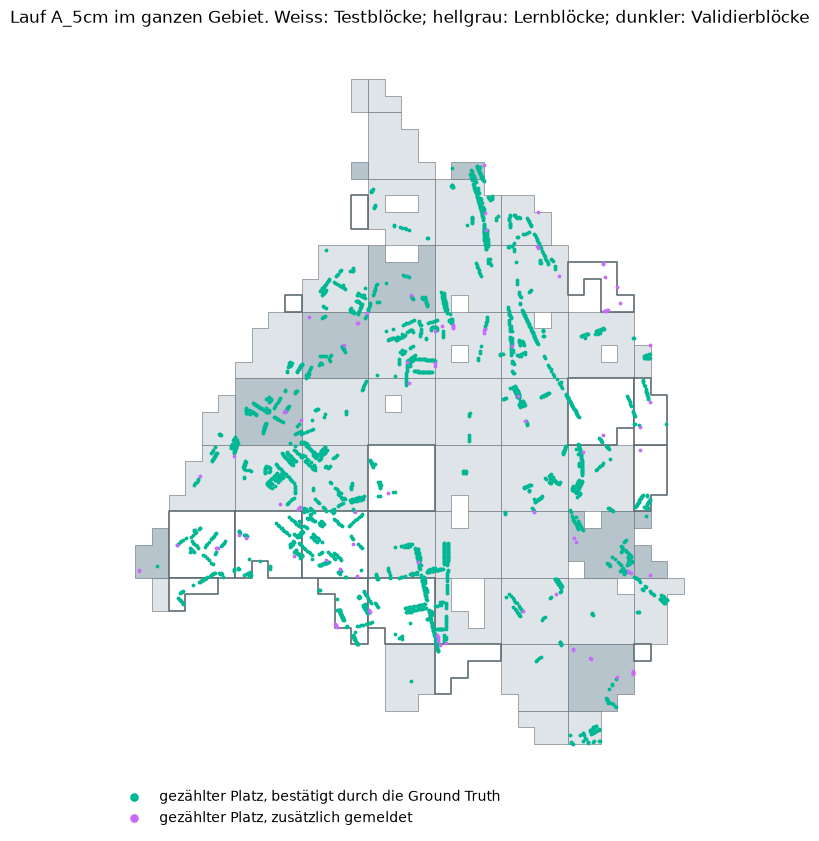

In [29]:
# Abbildung: das ganze Gebiet für den Lauf A_5cm. Blöcke nach ihrer Rolle, darüber die Punkte nach ihrem Status
punkte = gpd.read_file(DATEN / "parkplaetze_A_5cm.gpkg", layer="plaetze")
bloecke = ausschnitte.dissolve("block")[["gruppe", "geometry"]]      # Ausschnitte eines Blocks zu einer Fläche verschmelzen
ROLLE = {"lernen": "#dfe4e8", "validieren": "#b8c4cc", "testen": "#ffffff"}      # Grautöne für die Rolle; Testblöcke weiss
fig, ax = plt.subplots(figsize=(9, 9.5))
for gruppe, farbe in ROLLE.items():
    bloecke[bloecke.gruppe == gruppe].plot(ax=ax, color=farbe, edgecolor="#5f6b73", linewidth=1.2 if gruppe == "testen" else 0.4)
punkte[punkte.status == "bestätigt"].plot(ax=ax, color="#00b894", markersize=3, label="gezählter Platz, bestätigt durch die Ground Truth")
punkte[punkte.status == "zusätzlich gemeldet"].plot(ax=ax, color="#c86bfa", markersize=3, label="gezählter Platz, zusätzlich gemeldet")
ax.set_axis_off(); ax.legend(loc="upper left", bbox_to_anchor=(0, 0), frameon=False, markerscale=3)
ax.set_title("Lauf A_5cm im ganzen Gebiet. Weiss: Testblöcke; hellgrau: Lernblöcke; dunkler: Validierblöcke")
fig.savefig(ABB / "12_karte.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Jeder Punkt ist ein gezählter Platz des Laufs `A_5cm`. Grün: In der Fläche liegt ein sichtbares Feld der Ground Truth. Violett: Dort hat die Ground Truth kein sichtbares Feld. Die Flächen dahinter sind die Blöcke: weiss mit kräftigem Rand die Testblöcke, hellgrau die Lernblöcke, etwas dunkler die Validierblöcke.

**Was die Tabelle in Schritt 3 zeigt** (Lauf vom 27.11.2026). In den Lernblöcken zählt die Methode 93 bis 108 % der sichtbaren Felder, in den Testblöcken 79 bis 94 %. Auch der Anteil erkannter Felder ist in den Lernblöcken höher: 74 bis 92 % gegen 63 bis 83 % in den Testblöcken. Das ist der Grund, warum die Karte keine Prüfung ist: Auf Stellen, die das Netz vom Lernen kennt, sieht das Ergebnis besser aus als auf neuen Stellen. Die Zahlen der Testblöcke sind dieselben wie in Notebook 10.

## Grenzen dieser Karte

| Grenze | Folge |
| --- | --- |
| **Keine Prüfung.** | In Lern- und Validierblöcken kennt die Methode die Stellen schon. Wie gut sie auf neuen Stellen zählt, steht nur in Notebook 10 (Testblöcke). |
| **Punkte sind keine Felder.** | Die Punkte sind gleichmässig auf die gemeldete Fläche verteilt. Wo die einzelnen Felder aufgemalt sind, weiss die Methode nicht. |
| **"Erkannt" und "bestätigt" hängen an gesetzten Werten.** | Die Hälfte des Kästchens und 1 m Abstand sind Festlegungen (`01b`, 11.3, K6). Mit anderen Werten fielen einzelne Felder anders aus. |
| **Gelbe Markierungen zählen mit.** | Parkverbotsfelder und reservierte Felder stehen in der Ground Truth und werden vom Netz gemeldet (`01b`, 11.2). Ein Punkt auf der Karte ist darum nicht immer ein öffentlicher Parkplatz. |
| **Kleine Flächen stehen nicht einzeln in der Datei.** | Flächen unter einem halben Platz-Äquivalent zählen mit, sind im GeoPackage aber nur als Summe je Ausschnitt enthalten (Abschnitt 8, Schritt 1). |
| **Flächen enden am Rand eines Ausschnitts.** | Gerechnet wird je Ausschnitt. Eine Reihe, die über zwei Ausschnitte läuft, erscheint als zwei Flächen. |
| **Alle Grenzen aus Notebook 10 gelten weiter.** | Zum Beispiel: Die Methode zählt zu wenig; die Ground Truth stammt aus einem Durchgang einer Person. |

## Was wir gesehen haben

- Für alle 691 Ausschnitte und alle vier Läufe liegen gemeldete Flächen, Plätze als Punkte und der Abgleich mit der Ground Truth vor.
- Die drei Kontrollen zeigen, ob die Karte in den Testausschnitten dasselbe liefert wie die Notebooks 05, 08 und 09.
- Je Lauf gibt es ein GeoPackage mit vier Ebenen.

## Wie es weitergeht

Notebook 13 macht aus den GeoPackages das Dashboard: eine Karte im Browser mit Suche und Herunterladen.